### Installation et import

In [275]:
#!pip install kagglehub -q
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import re
import os

sns.set_style("whitegrid")
%matplotlib inline


### Téléchargement via kagglehub

In [276]:
path = kagglehub.dataset_download("llabhishekll/fraud-email-dataset")
print("path to dataset:", path)

# Lister les fichiers dans le dossier
for f in os.listdir(path):
    print(f)

path to dataset: C:\Users\Romuald\.cache\kagglehub\datasets\llabhishekll\fraud-email-dataset\versions\1
fraud_email_.csv


### Chargement du dataset

In [277]:
# Trouver le CSV automatiquement
csv_file = [f for f in os.listdir(path) if  f.endswith('.csv')]
print("CSV file found:", csv_file)

df = pd.read_csv(os.path.join(path, csv_file[0]))

print("Shape of the dataset:", df.shape)
print("Columns in the dataset:", df.columns)
df.head()

CSV file found: ['fraud_email_.csv']
Shape of the dataset: (11929, 2)
Columns in the dataset: Index(['Text', 'Class'], dtype='object')


,Text,Class
0,Supply Quality China's EXCLUSIVE dimensions at...,1
1,over. SidLet me know. Thx.,0
2,"Dear Friend,Greetings to you.I wish to accost ...",1
3,MR. CHEUNG PUIHANG SENG BANK LTD.DES VOEUX RD....,1
4,Not a surprising assessment from Embassy.,0


### Inspection des colonnes

In [278]:
print("=== Types de colonnes ===")
print(df.dtypes)
print("\n=== Aperçu des valeurs uniques par colonne ===")
for col in df.columns:
    print(f"{col} : {df[col].nunique()} valeurs uniques → ex: {df[col].unique()[:3]}")

=== Types de colonnes ===
Text     object
Class     int64
dtype: object

=== Aperçu des valeurs uniques par colonne ===
Text : 10249 valeurs uniques → ex: ["Supply Quality China's EXCLUSIVE dimensions at Unbeatable Price.Dear Sir, We are pleased to inform you as one of China's largest export & import sto=ne company-Wanlistone Group, The Group its subsidiaries specialize in the q=uarrying, processing and Sales of dimension stone, slab and tiles and dimen=sion stone products for the building materials sector and specialty markets==2E The Group operations are based in Xiamen, South of China, which is the lar=gest export and import business portals in China where Wanlistone owns and =operates various natural stone deposits with 6,000 square meters through th=e country. In addition to the quarries Wanlistone has a fully automated pro=cessing plant for the processing of the granite and marble and granite prod=ucts. Wanlistone supplies granite in raw block form, granite and marble tile and= s

###  Standardisation des noms de colonnes

In [279]:
# Adapter selon ce que la cellule 4 affiche
# On renomme pour avoir toujours 'text' et 'label'
df = df.rename(columns={
    'Text': 'text', 
    'Class': 'label' 
})

print(df['label'].unique())
print(df.head())

[1 0]
                                                text  label
0  Supply Quality China's EXCLUSIVE dimensions at...      1
1                         over. SidLet me know. Thx.      0
2  Dear Friend,Greetings to you.I wish to accost ...      1
3  MR. CHEUNG PUIHANG SENG BANK LTD.DES VOEUX RD....      1
4          Not a surprising assessment from Embassy.      0


### Valeurs Manquantes

In [280]:
print("=== Valeurs manquantes ===")
print(df.isnull().sum())
print(f"\n Pourcentage de NaN:")
print((df.isnull().sum()/len(df) * 100).round(2))

=== Valeurs manquantes ===
text     1
label    0
dtype: int64

 Pourcentage de NaN:
text     0.01
label    0.00
dtype: float64


**Commentaire:** Le dataset contient des valeurs manquantes uniquement dans la colonne `text`. 
La colonne `label` est complète — aucune supervision manquante.

### Gestion du NaN

In [281]:
before = len(df)

# 1. Supprimer uniquement les lignes sans texte
df = df.dropna(subset=['text'])

# 2. Supprimer les textes vides (whitespace pur) — peu importe le label
df = df[df['text'].astype(str).str.strip() != '']

# 3. Supprimer les lignes sans label
#df = df.dropna(subset=['label'])

# 4. Réinitialiser l'index
df = df.reset_index(drop=True)

after = len(df)

print(f"Lignes avant nettoyage : {before}")
print(f"Lignes après nettoyage : {after}")
print(f"Lignes supprimées      : {before - after}")

Lignes avant nettoyage : 11929
Lignes après nettoyage : 11926
Lignes supprimées      : 3


**Commentaire:** 3 lignes supprimées : textes NaN ou vides, inutilisables pour l'entraînement.
Les emails courts avec un label valide sont conservés — ils restent exploitables.

### Vérification des doublons

In [282]:
print("=== Doublons ===")
duplicates = df.duplicated(subset=['text']).sum()
print(f"Emails dupliqués : {duplicates} ({duplicates/len(df)*100:.1f}%)")
if duplicates > 0:
    df = df.drop_duplicates(subset=['text']).reset_index(drop=True)
    print(f"Après déduplication : {len(df)} lignes")
else:
    print("Aucun doublon détecté.")

=== Doublons ===
Emails dupliqués : 1679 (14.1%)
Après déduplication : 10247 lignes


**Commentaire:** 14.1% de doublons détectés et supprimés. Sans cette étape, les mêmes emails 
auraient pu se retrouver à la fois dans le train set et le test set (data leakage), 
et certains mots auraient eu un poids artificiel dans TF-IDF.

### Distribution des classes

=== Distribution des classes ===
label
0    5915
1    4332
Name: count, dtype: int64

label
0    57.7
1    42.3
Name: proportion, dtype: float64


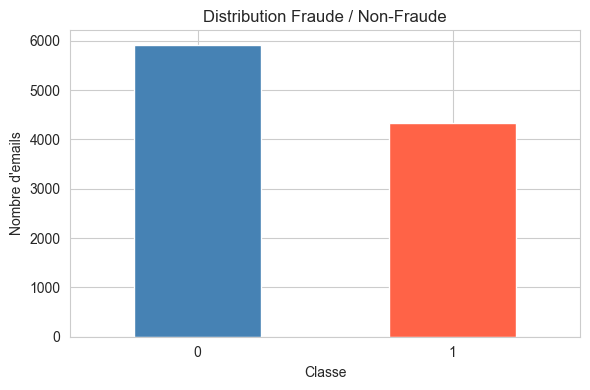

In [283]:
print("=== Distribution des classes ===")
print(df['label'].value_counts())
print()
print(df['label'].value_counts(normalize=True).round(3) * 100)

plt.figure(figsize=(6, 4))
df['label'].value_counts().plot(kind='bar', color=['steelblue', 'tomato'])
plt.title("Distribution Fraude / Non-Fraude")
plt.xlabel("Classe")
plt.ylabel("Nombre d'emails")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Commentaire:** Le dataset est déséquilibré : la classe majoritaire représente ~80% des données.
Ce déséquilibre justifie l'utilisation de SMOTE lors de l'entraînement pour éviter 
qu'un modèle naïf ne prédit toujours la classe majoritaire.

### Longueur des emails

=== Statistiques sur la longueur des emails ===
      text_length                                                            \
            count     mean      std  min      25%     50%      75%      max   
label                                                                         
0          5915.0   592.98  2749.96  1.0    42.00    98.0   223.00  77053.0   
1          4332.0  2410.88  3445.61  7.0  1238.75  2217.5  3057.25  63853.0   

      word_count                                                     
           count    mean     std  min    25%    50%    75%      max  
label                                                                
0         5915.0   93.09  423.44  1.0    8.0   17.0   38.0  11936.0  
1         4332.0  334.46  270.74  1.0  171.0  340.0  473.0  11662.0  


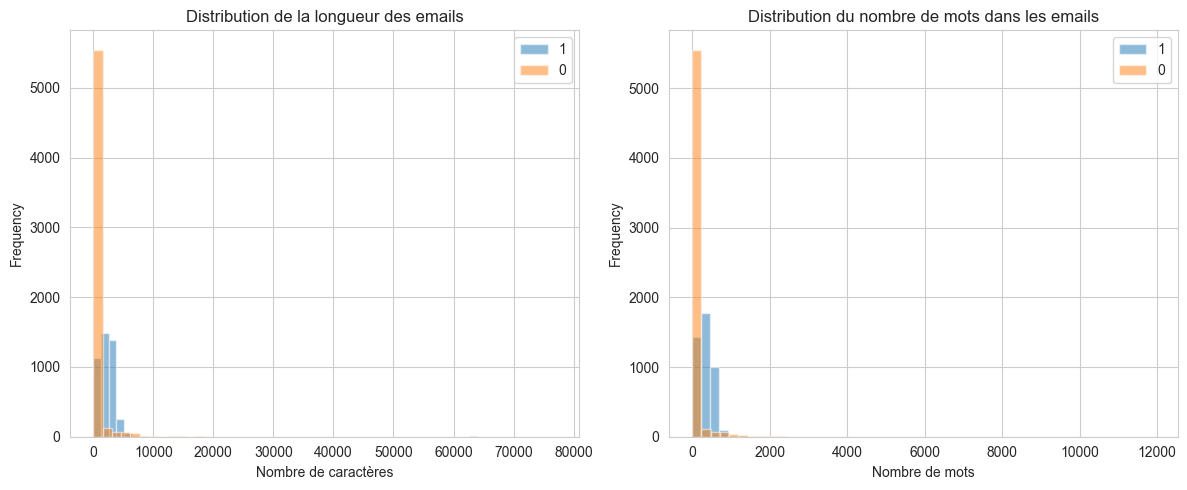

In [284]:
df['text_length'] = df['text'].astype(str).apply(len)
df['word_count'] = df['text'].astype(str).str.split().apply(len)

print("=== Statistiques sur la longueur des emails ===")
print(df.groupby('label')[['text_length', 'word_count']].describe().round(2))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
for label in df['label'].unique():
    df[df['label'] == label]['text_length'].plot(kind='hist', label=str(label), alpha=0.5, bins=50)
plt.title("Distribution de la longueur des emails")
plt.xlabel("Nombre de caractères")  
plt.legend()

plt.subplot(1, 2, 2)
for label in df['label'].unique():
    df[df['label'] == label]['word_count'].plot(kind='hist', label=str(label), alpha=0.5, bins=50)
plt.title("Distribution du nombre de mots dans les emails")
plt.xlabel("Nombre de mots")
plt.legend()
plt.tight_layout()
plt.show()


**Commentaire:** Les emails frauduleux sont en moyenne plus longs que les emails légitimes.
Une longue longueur de texte peut donc être un signal faible de fraude.
TF-IDF capturera ces différences via la fréquence des termes.

### Emails vide ou trop courts

In [285]:
print("=== Qualité des textes ===")
print(f"Textes NaN            : {df['text'].isna().sum()}")
print(f"Textes vides ('')     : {(df['text'].astype(str).str.strip() == '').sum()}")
print(f"Textes < 20 caractères: {(df['text_length'] < 20).sum()}")

=== Qualité des textes ===
Textes NaN            : 0
Textes vides ('')     : 0
Textes < 20 caractères: 615


**Commentaire:** Après nettoyage NaN, il ne reste aucun texte vide.
Les textes courts avec label valide sont conservés intentionnellement.

###  Mots les plus fréquents par classe

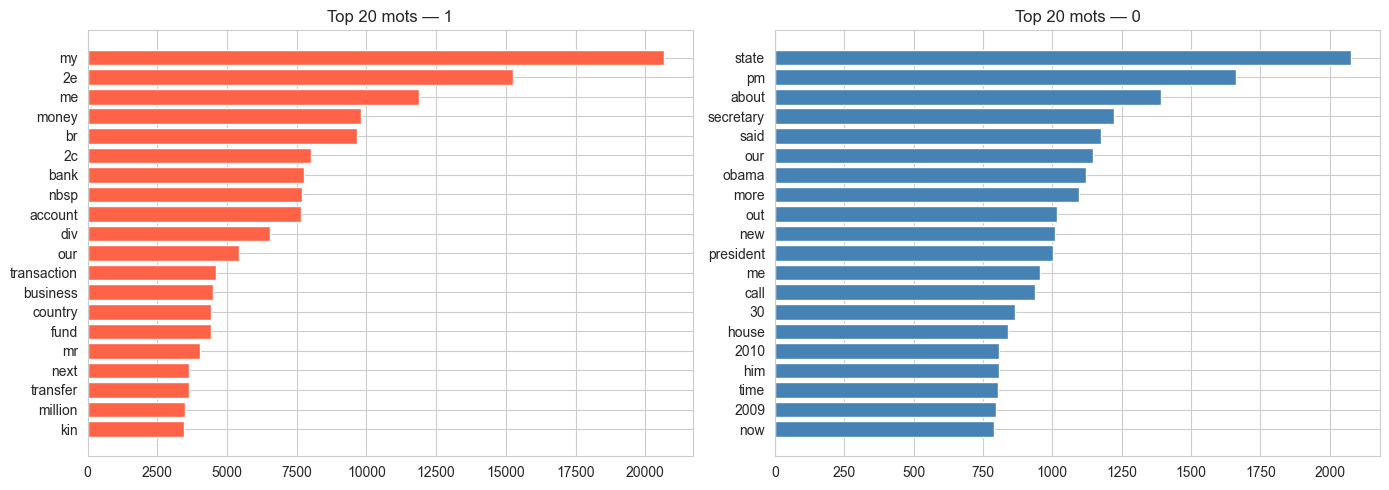

In [286]:
from sklearn.feature_extraction.text import CountVectorizer

def get_top_words_fast(texts, n=20):
    stopwords_list = ['the','a','an','to','of','and','in','is','it','for','on',
                      'this','with','you','your','we','are','be','at','as','or',
                      'that','have','has','will','was','not','from','by','can',
                      'do','all','so','up','if','been','they','their','but','no',
                      'one','would','what','he','she','his','her','its','who',
                      'how','when','where','also','any','there','which','just',
                      'than','then','some','had','were','did','get','am','us']
    vec = CountVectorizer(stop_words=stopwords_list, max_features=500, min_df=2)
    X = vec.fit_transform(texts.astype(str))
    counts = X.sum(axis=0).A1
    words = vec.get_feature_names_out()
    top_idx = counts.argsort()[::-1][:n]
    return [(words[i], counts[i]) for i in top_idx]

labels = df['label'].unique()
fig, axes = plt.subplots(1, len(labels), figsize=(7 * len(labels), 5))
colors = ['tomato', 'steelblue']
for i, label in enumerate(labels):
    top = get_top_words_fast(df[df['label'] == label]['text'])
    words, counts = zip(*top)
    ax = axes[i] if len(labels) > 1 else axes
    ax.barh(words[::-1], counts[::-1], color=colors[i % len(colors)])
    ax.set_title(f"Top 20 mots — {label}")
plt.tight_layout()
plt.show()

**Commentaire:** Les emails frauduleux contiennent des mots caractéristiques : "bank", "fund", "money", "transfer", "account"...
Les emails légitimes ont un vocabulaire plus varié et contextuel.
Ces patterns seront capturés par TF-IDF comme features discriminantes.

### Copie vers data/processed

In [287]:
import pathlib

# Sauvegarde du dataset nettoyé
project_root = pathlib.Path().resolve().parent
dest_processed = project_root / "Fraud-text-nlp" / "data" / "processed" / "emails_clean.csv"
dest_processed.parent.mkdir(parents=True, exist_ok=True)
df[['text', 'label']].to_csv(dest_processed, index=False)
print(f"Dataset nettoyé sauvegardé : {dest_processed}")

# Résumé
total = len(df)
print("\n" + "=" * 40)
print("        RÉSUMÉ EDA")
print("=" * 40)
print(f"Total emails         : {total}")
for label in df['label'].unique():
    count = (df['label'] == label).sum()
    print(f"Classe '{label}'        : {count} ({count/total*100:.1f}%)")
print(f"Longueur moy. texte  : {df['text_length'].mean():.0f} chars")
print(f"Mots moyens par email: {df['word_count'].mean():.0f}")
print(f"NaN dans text        : {df['text'].isna().sum()}")
print("=" * 40)
print("→ Déséquilibre détecté : SMOTE sera appliqué lors du training")
print("→ Fichier sauvegardé   : data/processed/emails_clean.csv")

Dataset nettoyé sauvegardé : D:\Cours\Projets\Fraud-text-nlp\data\processed\emails_clean.csv

        RÉSUMÉ EDA
Total emails         : 10247
Classe '1'        : 4332 (42.3%)
Classe '0'        : 5915 (57.7%)
Longueur moy. texte  : 1362 chars
Mots moyens par email: 195
NaN dans text        : 0
→ Déséquilibre détecté : SMOTE sera appliqué lors du training
→ Fichier sauvegardé   : data/processed/emails_clean.csv


**Commentaire:** ## Conclusions EDA
- Vocabulaire frauduleux identifiable → TF-IDF adapté comme feature extractor
- Fichier `emails_clean.csv` prêt pour le preprocessing 